# Oppgave 5 – TSM-gradient langs et transekt (HYPSO-2 vs. Sentinel-3 OLCI)

Samme transekt som i oppgave 3 (definert i `felles.py`), men nå med `tsm(yoc)`.

Steg:
1. Les inn, masker og beskjær `tsm(yoc)`
2. Hent TSM i nærmeste piksel langs transektet for begge sensorene
3. Vis transektet på TSM-kartene, og plott TSM mot lengdegrad

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")  # ufarlige cartopy-advarsler

import felles  # egne funksjoner: innlesing, maskering, beskjæring, transekt

# Felles fargeskala for TSM [g m^-3] (samme som i oppgave 4)
VMIN, VMAX = 0.1, 20

## 1. Les inn, masker og beskjær data

In [2]:
lat_h2, lon_h2, tsm_h2, flagg_h2 = felles.les_produkt(felles.FIL_H2, "tsm(yoc)")
lat_s3, lon_s3, tsm_s3, flagg_s3 = felles.les_produkt(felles.FIL_S3, "tsm(yoc)")

# Fjern land, sky, flaggede piksler og ekstreme verdier
tsm_h2 = felles.masker(tsm_h2, flagg_h2)
tsm_s3 = felles.masker(tsm_s3, flagg_s3)

# Beskjær Sentinel-3 til HYPSO-2-omrisset
kant_lon, kant_lat = felles.hypso_omriss(lat_h2, lon_h2)
lat_s3, lon_s3, tsm_s3 = felles.beskjaer_til_hypso(lat_s3, lon_s3, tsm_s3, kant_lon, kant_lat)

## 2. Hent TSM langs transektet

Samme metode som i oppgave 3: punkter hver 150 m, verdien i nærmeste piksel
(maks 600 m unna for HYPSO-2 og 300 m for Sentinel-3), pluss en glidende median over ca. 1,5 km.

In [3]:
t_lat, t_lon, t_km = felles.transekt_punkter()
print(f"Start: {t_lat[0]:.2f}°N {t_lon[0]:.2f}°E   Slutt: {t_lat[-1]:.2f}°N {t_lon[-1]:.2f}°E   "
      f"Lengde: {t_km[-1]:.1f} km")

tr_h2 = felles.hent_langs_transekt(lat_h2, lon_h2, tsm_h2, t_lat, t_lon, maks_avstand_m=600)
tr_s3 = felles.hent_langs_transekt(lat_s3, lon_s3, tsm_s3, t_lat, t_lon, maks_avstand_m=300)

def glidende_median(y, vindu=11):
    """Glidende median som tåler NaN (vindu = antall punkter, 11 x 150 m ≈ 1,5 km)."""
    halv = vindu // 2
    ut = np.full_like(y, np.nan)
    for i in range(y.size):
        biter = y[max(0, i - halv): i + halv + 1]
        if np.isfinite(biter).sum() >= halv:     # krever at minst halve vinduet har data
            ut[i] = np.nanmedian(biter)
    return ut

glatt_h2 = glidende_median(tr_h2)
glatt_s3 = glidende_median(tr_s3)

print(f"Gyldige punkter: HYPSO-2 {np.isfinite(tr_h2).sum()}/{tr_h2.size},  "
      f"Sentinel-3 {np.isfinite(tr_s3).sum()}/{tr_s3.size}")

Start: 44.60°N 12.35°E   Slutt: 44.45°N 13.45°E   Lengde: 89.0 km


Gyldige punkter: HYPSO-2 575/594,  Sentinel-3 571/594


## 3a. Transektet tegnet inn på TSM-kartene

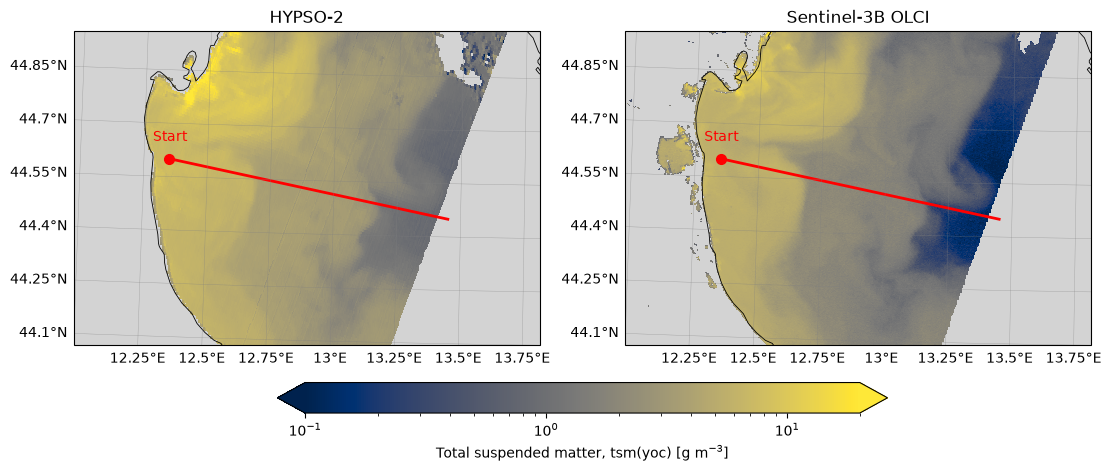

In [4]:
proj = ccrs.UTM(zone=33)
data_crs = ccrs.PlateCarree()
norm = LogNorm(vmin=VMIN, vmax=VMAX)

# Zoom inn rundt transektet
marg = 0.35
utsnitt = [t_lon.min() - marg, t_lon.max() + marg, t_lat.min() - marg, t_lat.max() + marg]

fig, akser = plt.subplots(1, 2, figsize=(11, 4.8), subplot_kw={"projection": proj},
                          constrained_layout=True)

for ax, lon, lat, tsm, tittel in [
    (akser[0], lon_h2, lat_h2, tsm_h2, "HYPSO-2"),
    (akser[1], lon_s3, lat_s3, tsm_s3, "Sentinel-3B OLCI"),
]:
    bilde = ax.pcolormesh(lon, lat, tsm, transform=data_crs, norm=norm,
                          cmap="cividis", shading="auto")
    ax.plot(t_lon, t_lat, transform=data_crs, color="red", lw=2)                        # transektet
    ax.plot(t_lon[0], t_lat[0], "o", transform=data_crs, color="red", ms=7)             # start (kyst)
    ax.text(t_lon[0], t_lat[0] + 0.05, "Start", transform=data_crs, color="red", ha="center")
    ax.set_facecolor("lightgray")  # grått = ingen data
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.6)
    ax.set_extent(utsnitt, crs=data_crs)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    ax.set_title(tittel)

cbar = fig.colorbar(bilde, ax=akser, orientation="horizontal", shrink=0.6, pad=0.04, extend="both")
cbar.set_label("Total suspended matter, tsm(yoc) [g m$^{-3}$]")
fig.savefig("oppgave5_transekt_kart.png", dpi=200, bbox_inches="tight")
plt.show()

## 3b. TSM langs transektet

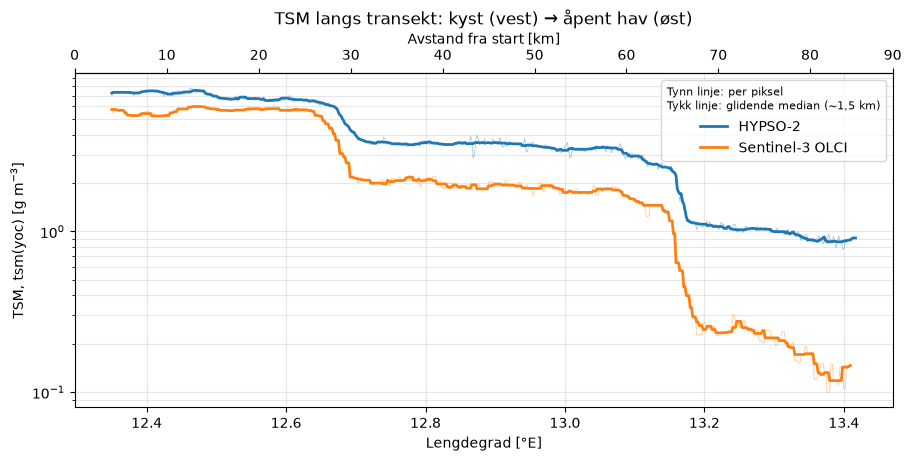

In [5]:
farge_h2, farge_s3 = "tab:blue", "tab:orange"

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)

# Rådata (tynne, gjennomsiktige) + glattet kurve (tykk)
ax.plot(t_lon, tr_h2, color=farge_h2, lw=0.6, alpha=0.4)
ax.plot(t_lon, tr_s3, color=farge_s3, lw=0.6, alpha=0.4)
ax.plot(t_lon, glatt_h2, color=farge_h2, lw=2, label="HYPSO-2")
ax.plot(t_lon, glatt_s3, color=farge_s3, lw=2, label="Sentinel-3 OLCI")

ax.set_yscale("log")
ax.set_xlabel("Lengdegrad [°E]")
ax.set_ylabel("TSM, tsm(yoc) [g m$^{-3}$]")
ax.set_title("TSM langs transekt: kyst (vest) → åpent hav (øst)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Tynn linje: per piksel\nTykk linje: glidende median (~1,5 km)", title_fontsize=8)

# Ekstra x-akse øverst med avstand fra start
topp = ax.secondary_xaxis("top", functions=(
    lambda lon: np.interp(lon, t_lon, t_km), lambda km: np.interp(km, t_km, t_lon)))
topp.set_xlabel("Avstand fra start [km]")

fig.savefig("oppgave5_transekt_tsm.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Tall til tolkningen

In [6]:
# Sammenlign kyst-delen og havdelen av transektet (første og siste 20 km)
for navn, tr in [("HYPSO-2", tr_h2), ("Sentinel-3", tr_s3)]:
    kyst = np.nanmedian(tr[t_km <= 20])
    hav = np.nanmedian(tr[t_km >= t_km[-1] - 20])
    print(f"{navn:11s} kyst (0–20 km): {kyst:6.2f}   hav (siste 20 km): {hav:5.2f} g m^-3   "
          f"forhold kyst/hav: {kyst / hav:4.1f}")

# Forhold mellom sensorene der begge har data
begge = np.isfinite(tr_h2) & np.isfinite(tr_s3)
forhold = tr_h2[begge] / tr_s3[begge]
print(f"\nMedian forhold HYPSO-2 / Sentinel-3: hele transektet {np.median(forhold):.2f}, "
      f"kyst (0–20 km) {np.median(forhold[t_km[begge] <= 20]):.2f}, "
      f"hav (siste 20 km) {np.median(forhold[t_km[begge] >= t_km[-1] - 20]):.2f}")
print(f"Korrelasjon (log10 TSM): {np.corrcoef(np.log10(tr_h2[begge]), np.log10(tr_s3[begge]))[0, 1]:.2f}")

HYPSO-2     kyst (0–20 km):   7.13   hav (siste 20 km):  0.99 g m^-3   forhold kyst/hav:  7.2
Sentinel-3  kyst (0–20 km):   5.69   hav (siste 20 km):  0.21 g m^-3   forhold kyst/hav: 27.2

Median forhold HYPSO-2 / Sentinel-3: hele transektet 1.78, kyst (0–20 km) 1.24, hav (siste 20 km) 4.87
Korrelasjon (log10 TSM): 0.99


## Answers for the report (Task 5)

The same 89 km transect as in Task 3 was used, from the Po plume (44.60°N, 12.35°E) to clearer water (44.45°N, 13.45°E).
This makes the TSM and Chl-a gradients directly comparable.

**How does TSM change from nearshore to offshore?** TSM decreases offshore for both sensors.
As for Chl-a, the decrease happens in steps separated by fronts:
- *0–28 km (to about 12.65°E), Po plume:* highest values, about 5–7 g m⁻³.
- *About 12.7°E:* a first drop to the transition water, where TSM is about 2–3 g m⁻³.
- *13.15°E:* a second, sharper drop, at the same position as the Chl-a front.
- *Offshore:* the lowest values, about 1 g m⁻³ for HYPSO-2 and 0.1–0.25 g m⁻³ for OLCI.

The coincident TSM and Chl-a fronts show that the Po plume carries both suspended sediment and nutrients/phytoplankton.
The fronts mark the boundaries between distinct water masses.

**Do HYPSO-2 and OLCI show similar patterns?** Yes. The shape of the two profiles is almost identical (r = 0.99 for log₁₀ TSM), and both sensors place the fronts at exactly the same positions.
This agreement is much better than for Chl-a (r = 0.88), and the plume is clearly visible to both sensors.
The difference lies in the absolute level: HYPSO-2 is higher along the whole transect.
The ratio HYPSO-2/OLCI increases from about 1.2 near the coast to about 5 offshore, and the coast/offshore ratio is therefore 7 for HYPSO-2 and 27 for OLCI.

A bias that grows as the signal becomes weaker points to an additive offset in the HYPSO-2 reflectance, not to a different water composition.
HYPSO-2 Rrs(665) is about 2.5–3× higher than OLCI's (Task 3, section 6).
In turbid water, where the red signal is strong, a small offset matters little.
In clear water, where the true red signal is close to zero, the same offset dominates and inflates the TSM.
Residual errors in atmospheric correction (e.g., aerosol or adjacency effects) and in radiometric calibration of HYPSO-2 are the most likely sources.
The time difference of 1.5 h may shift the front positions slightly, but it cannot explain a systematic, signal-dependent bias.